In [1]:
'''
looking at double streak stuff for fed's random forest or whatever
'''

"\nlooking at double streak stuff for fed's random forest or whatever\n"

In [131]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
# import scipy.ndimage as snm


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
# import implantation_functions as imp
# from tensorflow import keras
import get_postage_stamps as gpsf
import fitting

# from scipy.ndimage import sobel
# from scipy.signal import find_peaks
import importlib

In [8]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [49]:
fpath = (
            "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
            + '1020'
            + "_minus_extras/"
        )

fname = 'ztf_20221020148032_000686_zg_c05_x_0002.fits.fz'
path = fpath + fname
hdul = fits.open(path)
#13, 64, 100, 0, ...


In [50]:
image = hdul[1].data

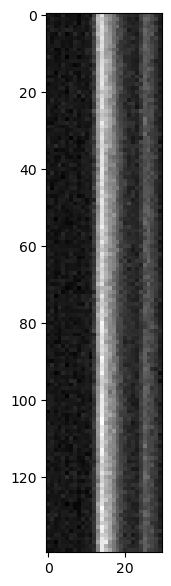

In [9]:
plt.imshow(image[1000:1140,50:80])
#plot with tracking

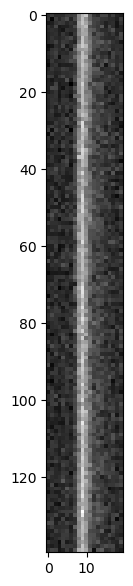

In [10]:
plt.imshow(image[1000:1140,625:645])

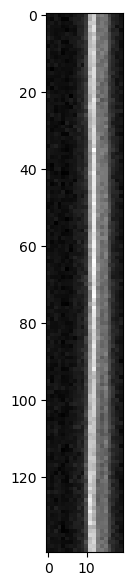

In [27]:
plt.imshow(image[1000:1140,2485:2505])

In [30]:
# fpath = (
#             "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
#             + '1020'
#             + "_minus_extras/"
#         )

# fname = 'ztf_20221020148032_000686_zg_c05_x

xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
xy_file = xy_path+"ztf_20221020148032_000686_zg_c05_x_1.fits"

In [31]:
xys = fits.open(xy_file)

In [35]:
data = xys[1].data  

In [36]:
data

FITS_rec([(1237.,  106.), (1966., 2273.), (2793., 2244.), ( 557., 2309.),
          (2468., 1535.), (2080., 1989.), ( 385., 1692.), ( 595., 2800.),
          (2497., 1058.), ( 128., 2400.), (2273., 1615.), (1054.,  757.),
          (2723.,  435.), (  64.,  100.), (1102., 2897.), (1955., 2277.),
          (2701.,  100.), (1831.,  342.), (2120., 1468.), (1464., 1201.),
          (2481.,  690.), ( 803., 1469.), ( 634., 2900.), (2587., 2848.),
          (2058., 2074.), (1939., 1246.), (1207., 2559.)],
         dtype=(numpy.record, [('X', '>f8'), ('Y', '>f8')]))

In [101]:
start_path = "/lustre/lrspec/ZTF_data/starts_to_delete/"
start = fits.open(start_path+"ztf_20221020148032_000686_zg_c05_x.fits.fz")

In [102]:
beginning = start[1].data

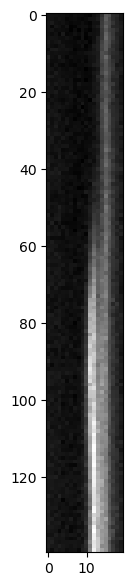

In [39]:
plt.imshow(beginning[1000:1140,2485:2505])

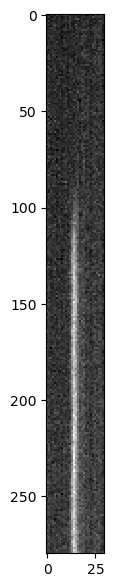

In [50]:
plt.imshow(beginning[2800:3080,620:650])

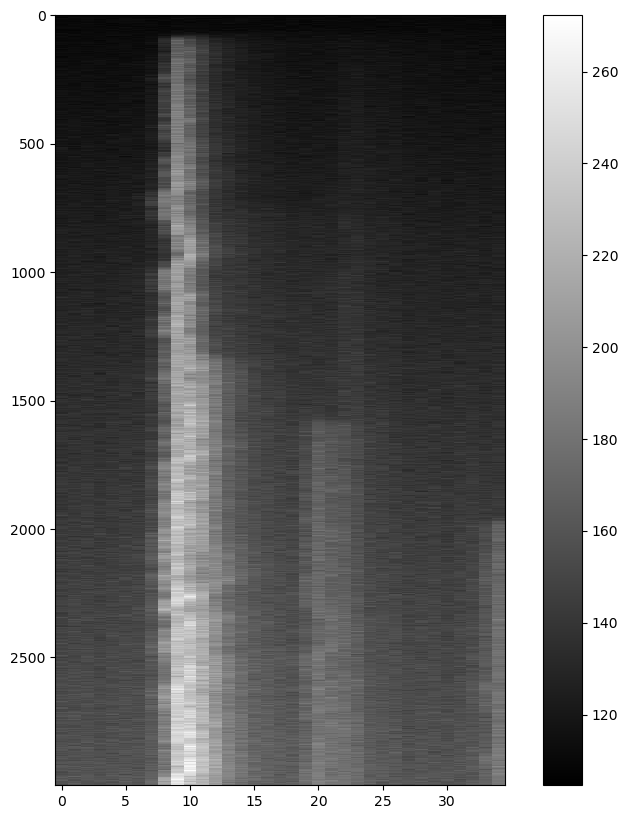

In [122]:
fig, ax = plt.subplots(figsize=(10,10))
plt.imshow(beginning[1:3000,55:90], aspect=.02)
plt.colorbar()

In [83]:
xcol = 64#634.
ycol =100 # 2900
lc_filename = 'lightcurve_'+'ztf_20221020148032_000686_zg_c05_x_0002'+'_'+'1'+'_'+f'{int(xcol):04}'+'_'+f'{int(ycol):04}'+'.csv'

In [46]:
tot, maxcols = rff.get_tot_csv(None, None, half_aperture=2, lc_filename=lc_filename)

In [84]:
tot5, maxcol5s = rff.get_tot_csv(None, None, half_aperture=5, lc_filename=lc_filename)

In [66]:
maxcols

0       64.0
1       64.0
2       64.0
3       64.0
4       64.0
        ... 
3075    65.0
3076    65.0
3077    65.0
3078    65.0
3079    65.0
Name: max_col, Length: 3080, dtype: float64

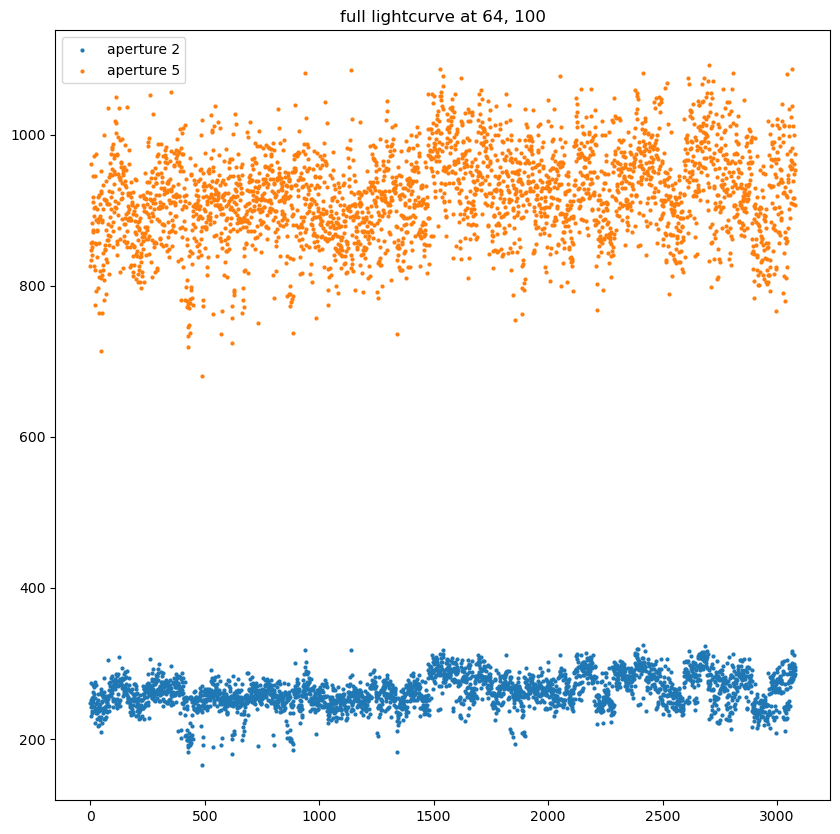

In [99]:
fig, ax = plt.subplots(figsize=(10,10))
plt.scatter(range(len(tot)), tot, label = "aperture 2", s=4)
plt.scatter(range(len(tot5)), tot5, label="aperture 5", s=4)
plt.title("full lightcurve at 64, 100")
plt.legend()
# plt.ylim(0,1120)

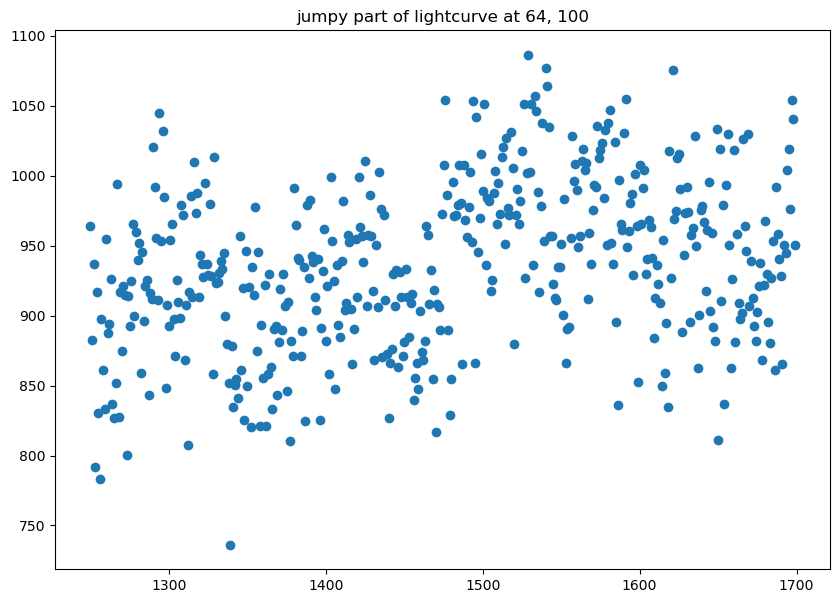

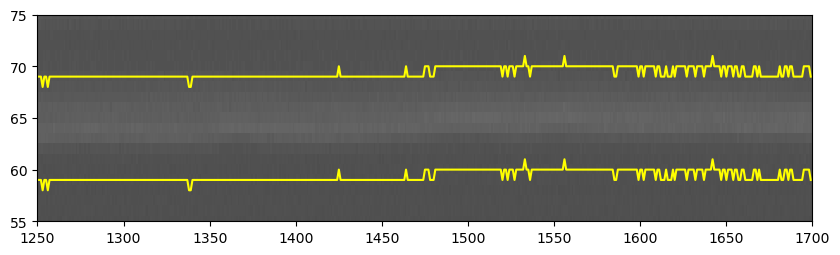

In [87]:
xstart = 1250
xend = 1700
plt.scatter(range(len(tot5))[xstart:xend], tot5[xstart:xend])
plt.title("jumpy part of lightcurve at 64, 100")
plt.show()
plt.imshow(np.sqrt(image).T, clim=.00001, aspect=6) #[1000:1140,50:80]
plt.plot(maxcols[xstart:xend]-5, c='yellow')
plt.plot(maxcols[xstart:xend]+5, c='yellow')
plt.ylim(55,75)
plt.xlim(xstart, xend)
plt.figsize=(10,47)
plt.show()

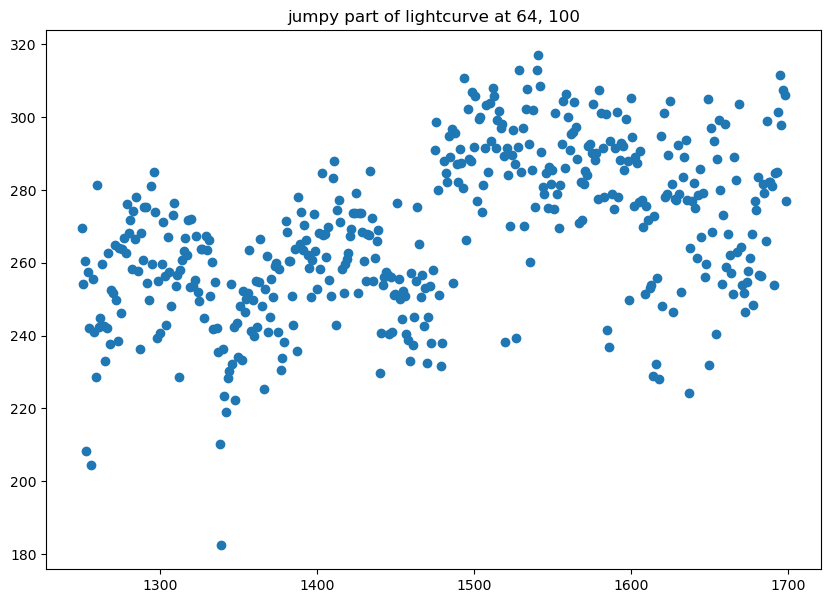

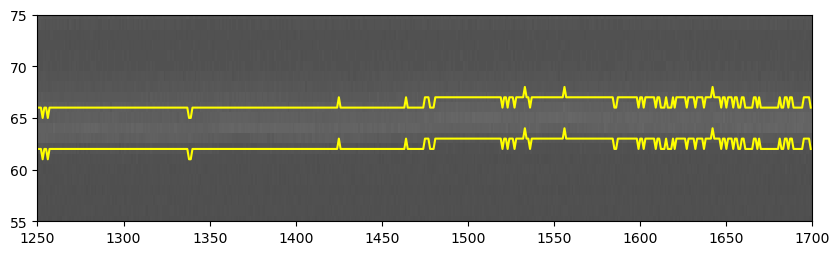

In [81]:
xstart = 1250
xend = 1700
plt.scatter(range(len(tot))[xstart:xend], tot[xstart:xend])
plt.title("jumpy part of lightcurve at 64, 100")
plt.show()
plt.imshow(np.sqrt(image).T, clim=.00001, aspect=6) #[1000:1140,50:80]
plt.plot(maxcols[xstart:xend]-2, c='yellow')
plt.plot(maxcols[xstart:xend]+2, c='yellow')
plt.ylim(55,75)
plt.xlim(xstart, xend)
plt.figsize=(10,47)
plt.show()

In [18]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

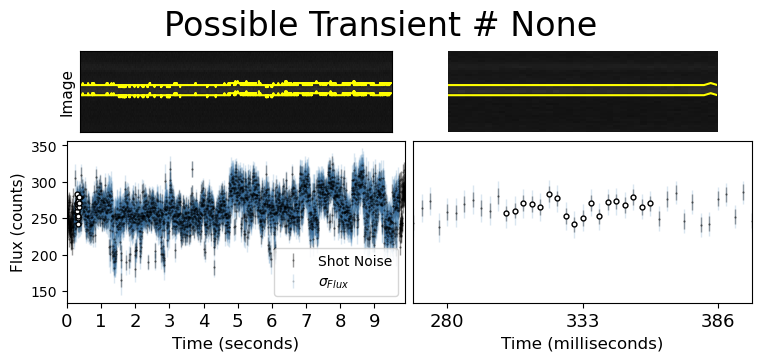

In [48]:
rff.plot_time_series_again_aperture(None, None, fname='ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
                                    lc_filename=lc_filename, quad=1, row=100,col=64, plot_tracking=True)

In [26]:
old_lcfpath = '/lustre/lrspec/ZTF_data/lightcurves/selection/'

In [28]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [139]:
# rff.plot_time_series_again_aperture

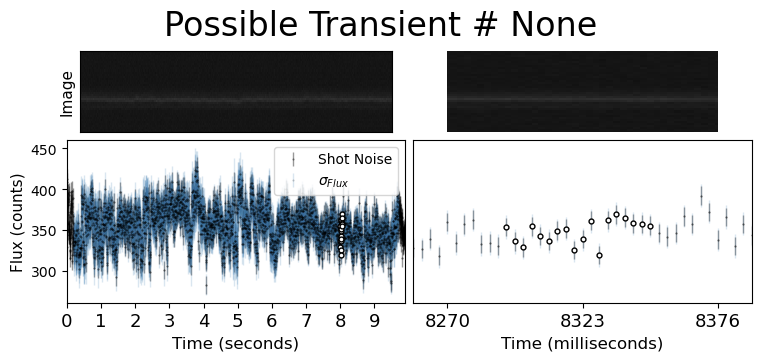

In [157]:
xcol = 2497#1966
ycol = 1058#2273
lc_filename = 'lightcurve_'+'ztf_20221020148032_000686_zg_c05_x_0002'+'_'+'1'+'_'+f'{int(xcol):04}'+'_'+f'{int(ycol):04}'+'.csv'

rff.plot_time_series_again_aperture(None, None, fname='ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
                                    lc_filename=lc_filename, quad=1, row=xcol,col=ycol, plot_tracking=True, lcfpath = old_lcfpath)

In [147]:
rff.plot_time_series_again_aperture?

Signature:
rff.plot_time_series_again_aperture(
    df,
    index,
    direcname='1020',
    half_aperture=2,
    tracking=True,
    title=None,
    plot_tracking=False,
    ylims=0,
    csv=True,
    lc_filename=None,
    fname=None,
    row=None,
    col=None,
    quad=None,
    lcfpath=None,
)
Docstring:
this plots a time series and image from a dataframe,
showing which pixels are included
inputs: dataframe, index, directory where the images live
aperture is 2*half_aperture+1
tracking can be True (tracks with brightest pixel)
or False (constant streak center pixel)
outputs: none, but plots.
NOTE: now uses loc intead of iloc, so it corresponds to the actual index!!
File:      ~/rwe/review_findings_functions.py
Type:      function

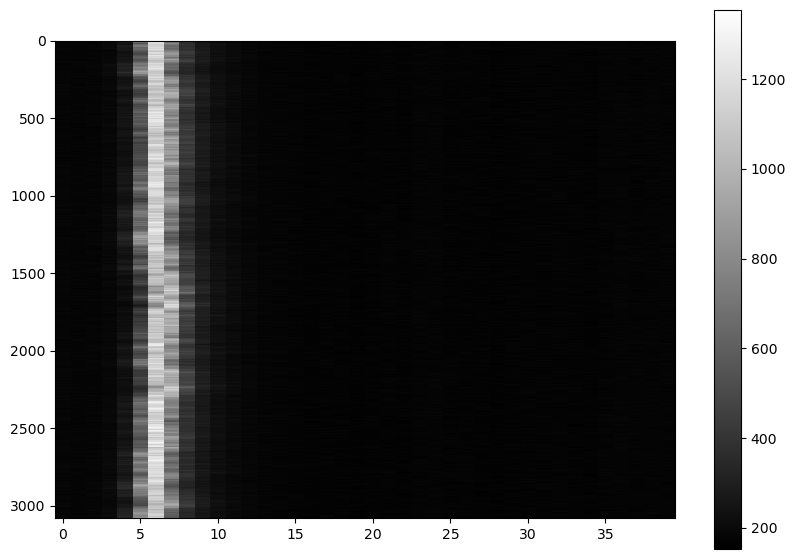

In [165]:
plt.imshow(image[:,1960:2000], aspect=.01 )
plt.colorbar()

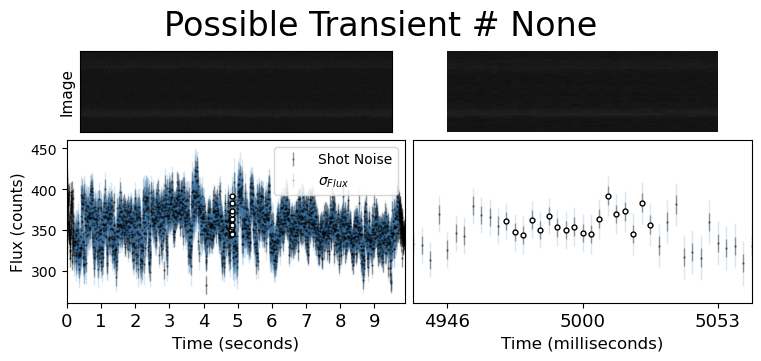

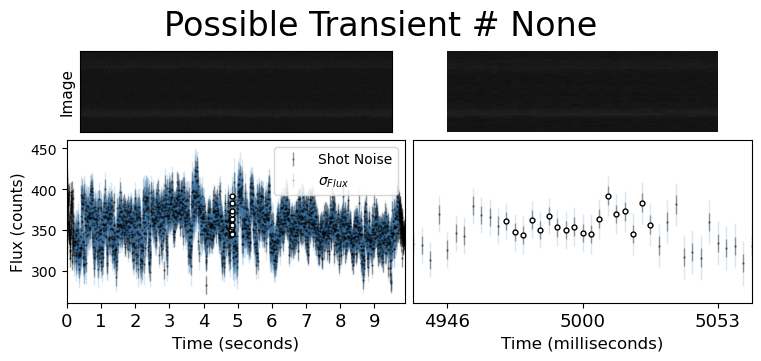

In [125]:
xcol = 2497.
ycol = 1058.
lc_filename = 'lightcurve_'+'ztf_20221020148032_000686_zg_c05_x_0002'+'_'+'1'+'_'+f'{int(xcol):04}'+'_'+f'{int(ycol):04}'+'.csv'

rff.plot_time_series_again_aperture(None, None, fname='ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
                                    lc_filename=lc_filename, quad=1, row=1500,col=645, plot_tracking=True, lcfpath = old_lcfpath)

rff.plot_time_series_again_aperture(None, None, fname='ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
                                    lc_filename=lc_filename, quad=1, row=1500,col=645, plot_tracking=True)

In [126]:
tot, maxcols = rff.get_tot_csv(None, None, half_aperture=2, lc_filename=lc_filename)

In [127]:
tot_old, maxcols_old = rff.get_tot_csv(None, None, half_aperture=2, lc_filename=lc_filename, lcfpath = old_lcfpath)

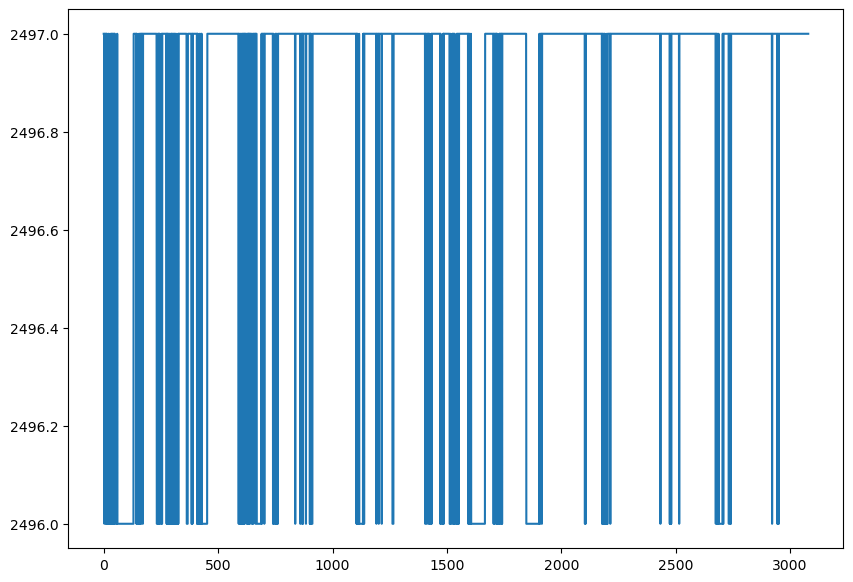

In [130]:
plt.plot(maxcols)

In [168]:
newimage = fits.open('/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020294271_000449_zr_c16_x_0012.fits.fz')

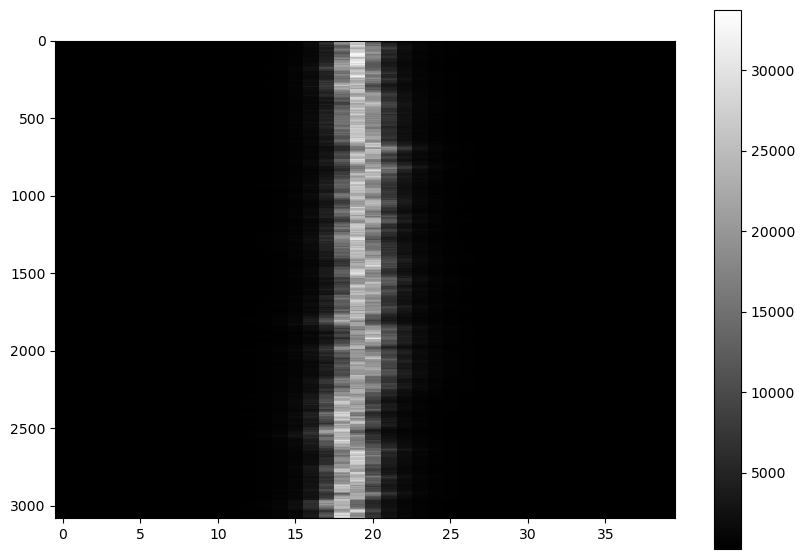

In [175]:
plt.imshow(newimage[2].data[:,2696-20:2696+20], aspect=.01)
plt.colorbar()


In [177]:
ycol = 1480
xcol = 2702
lc_filename = 'lightcurve_'+'ztf_20221020294271_000449_zr_c16_x_0012'+'_'+'2'+'_'+f'{int(xcol):04}'+'_'+f'{int(ycol):04}'+'.csv'

tot, maxcols = rff.get_tot_csv(None, None, half_aperture=2, lc_filename=lc_filename)

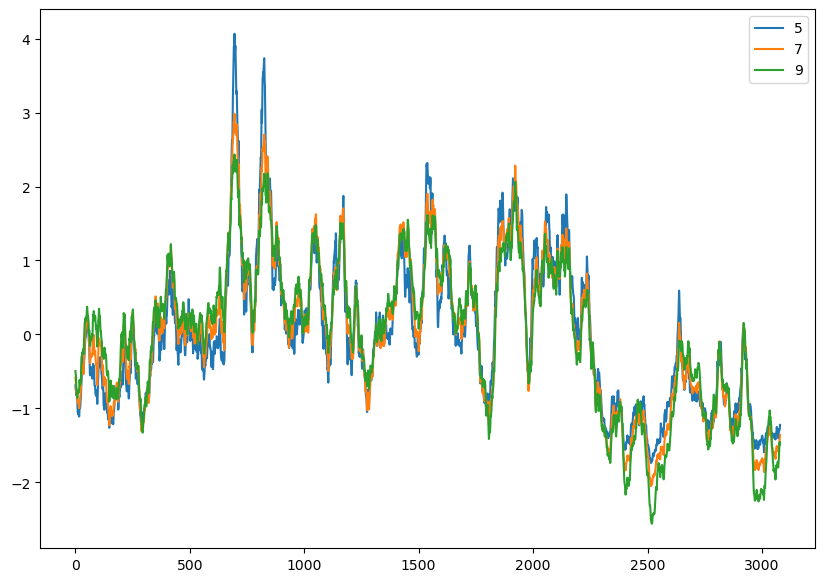

In [185]:
plt.plot((tot-tot.mean())/tot.std(), label = "5")
tot2, maxcols = rff.get_tot_csv(None, None, half_aperture=3, lc_filename=lc_filename)
plt.plot((tot2-tot2.mean())/tot2.std(), label="7")
tot3, maxcols = rff.get_tot_csv(None, None, half_aperture=4, lc_filename=lc_filename)
plt.plot((tot3-tot3.mean())/tot3.std(), label="9")
plt.legend()